Zadania laboratoryjne #1

Grupa:
- Kamil
- Igor Józefowicz 193257

Założenia:
- α ∈    (1°, 89°)
- v0 ∈   (1 m/s, 30 m/s)

Must cross:
- R1: x ∈ (4, 10), y = 2
- R3: x = 3, y ∈ (3, 9)

Must not cross:
- R2: x ∈ (7, 8), y = 2
- R4: x = 4, y ∈ (5, 6)

In [201]:
import numpy as np
import matplotlib.pyplot as plt
import math

repetitions = 100_000

alpha_min = 1
alpha_max = 89
alpha = alpha_min

v0_min = 1
v0_max = 30
v0 = v0_min

g = 10 # g = 10 m/s2


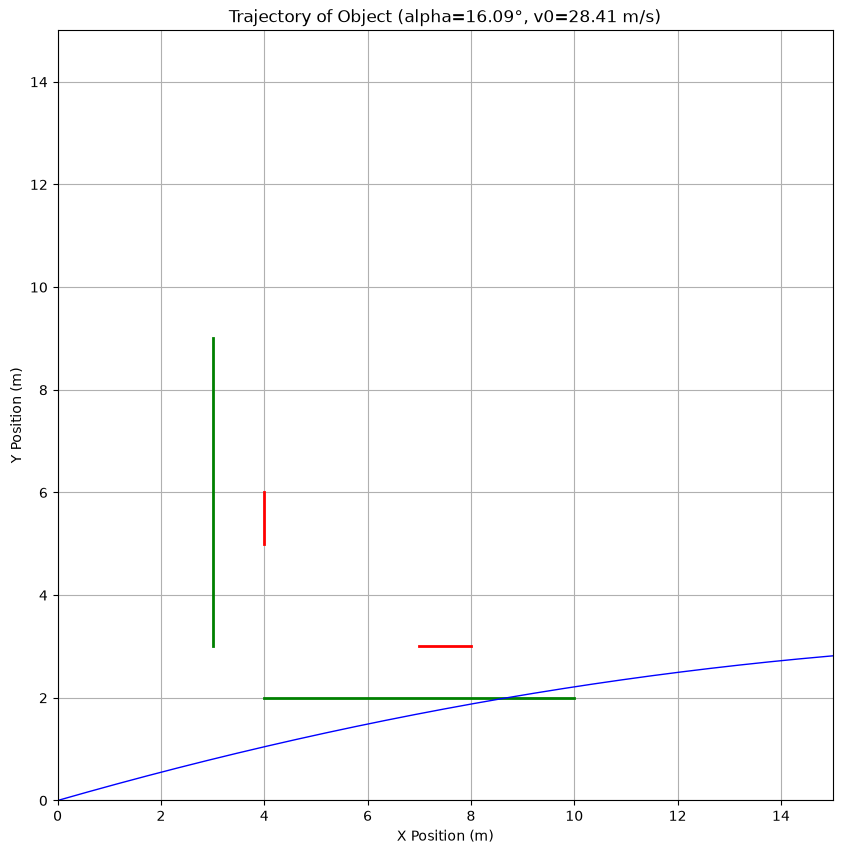

In [202]:
# Plots for must cross & must not cross regions

must_cross_lines = [
    (4, 2, 10, 2),  # R1  - horizontal
    (3, 3, 3, 9)    # R3 - vertical
]

must_not_cross_lines = [
    (7, 3, 8, 3),   # R2 - horizontal
    (4, 5, 4, 6)    # R4 - vertical
]

plot = plt.figure(figsize=(10, 10))

# start plot from (0, 0)
plt.xlim(0, 15)
plt.ylim(0, 15)

# must cross lines
for line in must_cross_lines:
    x1, y1, x2, y2 = line
    plt.plot([x1, x2], [y1, y2], 'g-', linewidth=2)

# must not cross lines
for line in must_not_cross_lines:
    x1, y1, x2, y2 = line
    plt.plot([x1, x2], [y1, y2], 'r-', linewidth=2)

# random trajectory within min & max
alpha = np.random.uniform(alpha_min, alpha_max)
v0 = np.random.uniform(v0_min, v0_max)

v0x = v0 * math.cos(math.radians(alpha))
v0y = v0 * math.sin(math.radians(alpha))

# calculate trajectory points
t = np.linspace(0, 2 * v0y / g, num=repetitions)
x = v0x * t
y = v0y * t - (1/2) * g * t**2

# draw object trajectory
plt.plot(x, y, 'b-', linewidth=1)

# show plot
plt.title(f'Trajectory of Object (alpha={alpha:.2f}°, v0={v0:.2f} m/s)')
plt.xlabel('X Position (m)')
plt.ylabel('Y Position (m)')
plt.grid()
plt.show()

# save plot to file next to the notebook
plot.savefig('trajectory_plot.png')

In [203]:
# x(t) = v0x * t
# t = x / v0x

# y(t) = v0y * t * (1/2) * g * t^2
# y(x) = v0y * (x / v0x) * (1/2) * g * (x / v0x)^2

# calculate if R3 must cross region (vertical) is crossed
is_R3_crossed = False

# height of trajectory in R3_x
R3_x = 3
R3_y_min = 3
R3_y_max = 9
trajectory_y_at_R3_x = v0y * (R3_x / v0x) - (1/2) * g * (R3_x / v0x)**2
print(f"Height of trajectory at R3_x={R3_x}: {trajectory_y_at_R3_x:.2f} m")

if trajectory_y_at_R3_x > R3_y_min and trajectory_y_at_R3_x < R3_y_max:
    is_R3_crossed = True

print(f"R3 must cross region crossed: {is_R3_crossed}\n")

# calculate if R4 must NOT cross region (vertical) is crossed
is_R4_crossed = False

# height of trajectory in R4_x
R4_x = 4
R4_y_min = 5
R4_y_max = 6
trajectory_y_at_R4_x = v0y * (R4_x / v0x) - (1/2) * g * (R4_x / v0x)**2
print(f"Height of trajectory at R4_x={R4_x}: {trajectory_y_at_R4_x:.2f} m\n")

if trajectory_y_at_R4_x > R4_y_min and trajectory_y_at_R4_x < R4_y_max:
    is_R4_crossed = True

print(f"R4 must not cross region crossed: {is_R4_crossed}")

if is_R3_crossed and not is_R4_crossed:
    print(f"Trajectory vertical regions ACCEPTED")
else:
    print(f"Trajectory vertical regions REJECTED")

Height of trajectory at R3_x=3: 0.81 m
R3 must cross region crossed: False

Height of trajectory at R4_x=4: 1.05 m

R4 must not cross region crossed: False
Trajectory vertical regions REJECTED


In [204]:
# calculate if R1 must cross region (horizontal) is crossed
is_R1_crossed = False
R1_y = 2
R1_x_min = 4
R1_x_max = 10
trajectory_y_at_R1_x_min = v0y * (R1_x_min / v0x) - (1/2) * g * (R1_x_min / v0x)**2
trajectory_y_at_R1_x_max = v0y * (R1_x_max / v0x) - (1/2) * g * (R1_x_max / v0x)**2

print(f"end={trajectory_y_at_R1_x_min:.2f} m, max={trajectory_y_at_R1_x_max:.2f} m")

if trajectory_y_at_R1_x_min > R1_y and trajectory_y_at_R1_x_max < R1_y:
    is_R1_crossed = True

print(f"R1 must cross region crossed: {is_R1_crossed}\n")

is_R3_crossed = False
R3_y = 3
R3_x_min = 3
R3_x_max = 9
trajectory_y_at_R3_x_min = v0y * (R3_x_min / v0x) - (1/2) * g * (R3_x_min / v0x)**2
trajectory_y_at_R3_x_max = v0y * (R3_x_max / v0x) - (1/2) * g * (R3_x_max / v0x)**2

print(f"end={trajectory_y_at_R3_x_min:.2f} m, max={trajectory_y_at_R3_x_max:.2f} m")

if trajectory_y_at_R3_x_min > R3_y and trajectory_y_at_R3_x_max < R3_y:
    is_R3_crossed = True

print(f"R3 must cross region crossed: {is_R3_crossed}\n")

if is_R1_crossed and not is_R3_crossed:
    print(f"Trajectory horizontal regions ACCEPTED")
else:
    print(f"Trajectory horizontal regions REJECTED")


end=1.05 m, max=2.21 m
R1 must cross region crossed: False

end=0.81 m, max=2.05 m
R3 must cross region crossed: False

Trajectory horizontal regions REJECTED


In [205]:
if is_R1_crossed and not is_R3_crossed and is_R3_crossed and not is_R4_crossed:
    print(f"Trajectory ACCEPTED")
else:
    print(f"Trajectory REJECTED")

# show the same plot trajectory once again 

Trajectory REJECTED


In [220]:
accepted_trajectories_count = 0

for i in range(repetitions):
    # Generate a new random trajectory
    alpha = np.random.uniform(alpha_min, alpha_max)
    v0 = np.random.uniform(v0_min, v0_max)

    v0x = v0 * math.cos(math.radians(alpha))
    v0y = v0 * math.sin(math.radians(alpha))

    is_R3_crossed = False

    # height of trajectory in R3_x
    R3_x = 3
    R3_y_min = 3
    R3_y_max = 9
    trajectory_y_at_R3_x = v0y * (R3_x / v0x) - (1/2) * g * (R3_x / v0x)**2

    if trajectory_y_at_R3_x > R3_y_min and trajectory_y_at_R3_x < R3_y_max:
        is_R3_crossed = True

    # calculate if R4 must NOT cross region (vertical) is crossed
    is_R4_crossed = False

    # height of trajectory in R4_x
    R4_x = 4
    R4_y_min = 5
    R4_y_max = 6
    trajectory_y_at_R4_x = v0y * (R4_x / v0x) - (1/2) * g * (R4_x / v0x)**2

    if trajectory_y_at_R4_x > R4_y_min and trajectory_y_at_R4_x < R4_y_max:
        is_R4_crossed = True



    # calculate if R1 must cross region (horizontal) is crossed
    is_R1_crossed = False
    R1_y = 2
    R1_x_min = 4
    R1_x_max = 10
    trajectory_y_at_R1_x_min = v0y * (R1_x_min / v0x) - (1/2) * g * (R1_x_min / v0x)**2
    trajectory_y_at_R1_x_max = v0y * (R1_x_max / v0x) - (1/2) * g * (R1_x_max / v0x)**2


    if trajectory_y_at_R1_x_min > R1_y and trajectory_y_at_R1_x_max < R1_y:
        is_R1_crossed = True


    is_R2_crossed = False
    R2_y = 3
    R2_x_min = 7
    R2_x_max = 8
    trajectory_y_at_R2_x_min = v0y * (R2_x_min / v0x) - (1/2) * g * (R2_x_min / v0x)**2
    trajectory_y_at_R2_x_max = v0y * (R2_x_max / v0x) - (1/2) * g * (R2_x_max / v0x)**2


    if trajectory_y_at_R2_x_min > R2_y and trajectory_y_at_R2_x_max < R2_y:
        is_R2_crossed = True



    if is_R1_crossed and not is_R2_crossed and is_R3_crossed and not is_R4_crossed:
        accepted_trajectories_count += 1

print(f"\nTotal accepted trajectories: {accepted_trajectories_count} out of {repetitions}")


Total accepted trajectories: 2504 out of 100000
